# Chapitre 3 - Cours 1 : Journaux append-only et index de hachage

Ce notebook ouvre le chapitre *Storage and Retrieval* par le point de vue de la base de
données : comment ranger les données qu'on lui confie, et comment les retrouver ? Il
couvre le début de la section *Data Structures That Power Your Database* et la
sous-section *Hash Indexes* : la base « bash » en deux fonctions, la notion d'index et
son coût, l'index de hachage en mémoire à la Bitcask, les segments, leur fusion et leur
compaction, et les détails qui font un vrai moteur (suppressions, reprise après panne,
écritures partielles, concurrence).

**Plan.**

1. La base de données la plus simple du monde : un fichier où l'on ajoute des lignes.
2. Qu'est-ce qu'un index ? Le compromis fondamental lecture contre écriture.
3. Un index de hachage en mémoire au-dessus du journal.
4. Segments, fusion et compaction : récupérer l'espace des valeurs écrasées.
5. Ce qui fait un vrai moteur : format binaire, suppressions, pannes, concurrence.
6. Pourquoi ajouter plutôt que modifier en place ? Et les limites de l'index de hachage.

In [1]:
import os
import tempfile
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import storage as S
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
WORK = tempfile.mkdtemp(prefix="ddia_stockage_")

## 1. La base de données la plus simple du monde (section *Data Structures That Power Your Database*)

**Le problème.** Une base de données ne fait, au fond, que deux choses : **ranger** ce
qu'on lui donne et le **rendre** quand on le redemande. Le livre part d'une base
clé-valeur écrite en deux fonctions bash : `db_set clé valeur` ajoute la ligne
`clé,valeur` à la fin d'un fichier, `db_get clé` parcourt le fichier et renvoie la
**dernière** valeur vue pour cette clé (d'où le `tail -n 1`).

En voici la traduction Python (`S.BashDB`). Mettre à jour une clé n'efface rien :
l'ancienne ligne reste, la nouvelle s'ajoute à la fin, et c'est l'ordre du fichier qui
dit laquelle est la plus récente.

In [2]:
db = S.BashDB(os.path.join(WORK, "database"))
db.set("75", '{"ville":"Paris","musées":["Louvre","Orsay"]}')
db.set("69", '{"ville":"Lyon","musées":["Confluences"]}')
db.set("75", '{"ville":"Paris","musées":["Louvre","Orsay","Quai Branly"]}')
print("db_get 75 ->", db.get("75"))
print("\ncontenu du fichier :")
print(open(db.path, encoding="utf-8").read())

db_get 75 -> {"ville":"Paris","musées":["Louvre","Orsay","Quai Branly"]}

contenu du fichier :
75,{"ville":"Paris","musées":["Louvre","Orsay"]}
69,{"ville":"Lyon","musées":["Confluences"]}
75,{"ville":"Paris","musées":["Louvre","Orsay","Quai Branly"]}



Ce fichier est un **journal** (*log*) au sens du livre : une suite d'enregistrements à
laquelle on ne fait **qu'ajouter**. Rien à voir avec les journaux applicatifs lisibles
par un humain : un journal de base de données est souvent binaire et à usage interne.

**Mesurons** les deux opérations. Écrire est très rapide (un ajout en fin de fichier,
sans rien relire) ; lire oblige à parcourir **tout** le fichier : la recherche coûte
$O(n)$ pour $n$ enregistrements. On compte les octets lus (mesure exacte et
reproductible) et on chronomètre (mesure indicative, qui dépend de la machine).

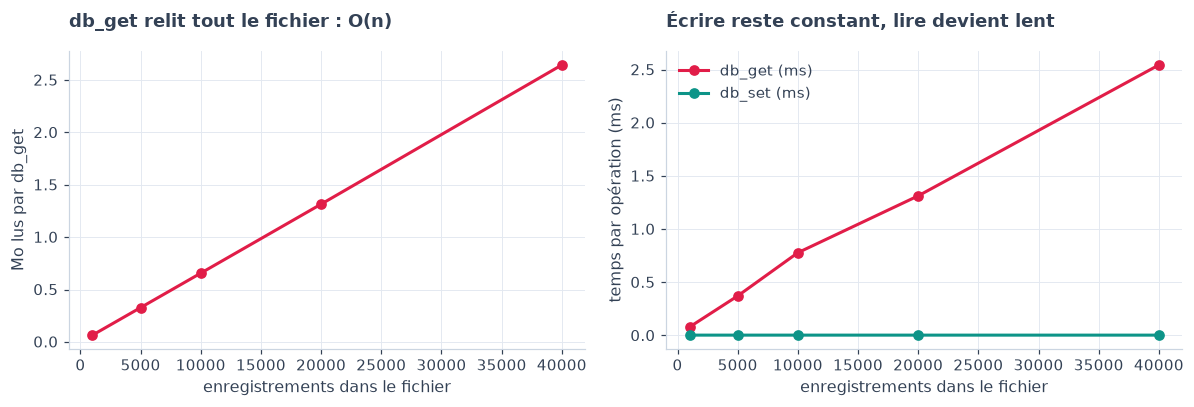

,enregistrements,taille_Mo,us_par_set,ms_par_get,octets_lus_par_get
0,1000,0.065,3.321,0.080,6.478e+04
1,5000,0.328,3.299,0.372,3.277e+05
2,10000,0.657,3.318,0.778,6.566e+05
3,20000,1.315,3.287,1.313,1.315e+06
4,40000,2.644,3.303,2.544,2.644e+06


In [3]:
rows = []
db = S.BashDB(os.path.join(WORK, "bash_perf"))
n_done = 0
for n in [1_000, 5_000, 10_000, 20_000, 40_000]:
    t0 = time.perf_counter()
    for i in range(n_done, n):
        db.set(str(i % (n // 2 + 1)), S.kv_value(i, size=60))
    t_set = (time.perf_counter() - t0) / (n - n_done)
    n_done = n
    db.bytes_scanned = 0
    t0 = time.perf_counter()
    for k in range(5):
        db.get(str(k * 7))
    t_get = (time.perf_counter() - t0) / 5
    rows.append(dict(enregistrements=n, taille_Mo=db.size() / 1e6, us_par_set=t_set * 1e6,
                     ms_par_get=t_get * 1e3, octets_lus_par_get=db.bytes_scanned / 5))
bash = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.plot(bash.enregistrements, bash.octets_lus_par_get / 1e6, "o-", color=ROSE)
ax.set_xlabel("enregistrements dans le fichier"); ax.set_ylabel("Mo lus par db_get")
ax.set_title("db_get relit tout le fichier : O(n)")
ax = axes[1]
ax.plot(bash.enregistrements, bash.ms_par_get, "o-", color=ROSE, label="db_get (ms)")
ax.plot(bash.enregistrements, bash.us_par_set / 1e3, "o-", color=TEAL, label="db_set (ms)")
ax.set_xlabel("enregistrements dans le fichier"); ax.set_ylabel("temps par opération (ms)")
ax.set_title("Écrire reste constant, lire devient lent")
ax.legend()
finish(fig)
plt.show()
bash

Le nombre d'octets lus par `db_get` est exactement la taille du fichier : doubler les
données double le coût d'une lecture. `db_set`, lui, garde un coût constant (quelques
microsecondes, essentiellement l'ouverture du fichier). Un vrai moteur fondé sur un
journal doit en plus gérer les écritures concurrentes, récupérer l'espace des vieilles
versions et survivre aux enregistrements à moitié écrits lors d'une panne : nous y
viendrons en section 5.

> **À retenir.** Ajouter en fin de fichier est l'écriture la plus simple et la plus
> rapide possible. Sans structure supplémentaire, la lecture coûte $O(n)$ : il faut un
> **index**.